In [30]:
# Librerias

import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay


### Paso 1: Carga los datos.

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/4GeeksAcademy/k-nearest-neighbors-project-tutorial/refs/heads/main/winequality-red.csv', sep=';')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Entre nuestras variables tenemes diversas escalas que van en rangos bastantes cercanos, entre 0 y 100, otras entre 0 y 1. La escalas no están tan alejadas/diferentes.

Lo pedido es predecir si un vino es MALO, MEDIO Y BUENO, y en la columna **'quality'** (que está en numérico) hay valores más altos que 3.



In [5]:
df['quality'].unique()

array([5, 6, 7, 4, 8, 3])

Para poder tener las clases que nos pidieron, vamos a mapear la columna **'quality'**

In [6]:
df['quality'] = df['quality'].map({3:'bad', 4:'bad', 5:'mid', 6:'mid', 7:'good', 8:'good'})

In [7]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,mid
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,mid
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,mid
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,mid
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,mid


### Paso 2: Entrena el modelo KNN

**Separa las variables independientes (X) del objetivo (y)**

**Divide en conjunto de entrenamiento y prueba (80/20)**

In [9]:
X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
493,8.7,0.690,0.31,3.0,0.086,23.0,81.0,1.00020,3.48,0.74,11.6
354,6.1,0.210,0.40,1.4,0.066,40.5,165.0,0.99120,3.25,0.59,11.9
342,10.9,0.390,0.47,1.8,0.118,6.0,14.0,0.99820,3.30,0.75,9.8
834,8.8,0.685,0.26,1.6,0.088,16.0,23.0,0.99694,3.32,0.47,9.4
705,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9


**Escala los datos si es necesario (¡muy recomendable con KNN!)**

In [11]:
scaler = StandardScaler()

X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

X_train_esc = pd.DataFrame(X_train_esc, columns=X_train.columns, index=X_train.index)
X_test_esc = pd.DataFrame(X_test_esc, columns=X_test.columns, index=X_test.index)

X_train_esc.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
493,0.218332,0.889712,0.192092,0.309726,-0.049642,0.691007,1.042934,1.846696,1.093500,0.458223,1.123177
354,-1.290166,-1.788783,0.652753,-0.805080,-0.455214,2.388473,3.593870,-3.004491,-0.400439,-0.401197,1.408272
342,1.494753,-0.784347,1.011045,-0.526378,0.599272,-0.957960,-0.991742,0.768655,-0.075669,0.515517,-0.587390
834,0.276351,0.861811,-0.063831,-0.665729,-0.009085,0.012020,-0.718427,0.089488,0.054238,-1.088733,-0.967516
705,0.044274,2.814880,-0.626861,2.399985,-0.313264,-0.472970,0.222990,1.199871,0.379008,-0.974144,-0.492358


**Entrena el modelo con un valor de k inicial.**

In [13]:
model = KNeighborsClassifier()

model.fit(X_train_esc, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['bad','good','mid']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [14]:
y_pred = model.predict(X_test_esc)

y_pred

array(['mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid',
       'mid', 'good', 'mid', 'mid', 'mid', 'mid', 'good', 'mid', 'mid',
       'good', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid',
       'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid',
       'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid',
       'mid', 'good', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'good',
       'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid',
       'mid', 'good', 'mid', 'mid', 'mid', 'good', 'mid', 'mid', 'mid',
       'mid', 'mid', 'mid', 'mid', 'good', 'mid', 'mid', 'good', 'mid',
       'good', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'good', 'mid',
       'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid',
       'mid', 'mid', 'mid', 'mid', 'good', 'mid', 'mid', 'mid', 'mid',
       'mid', 'mid', 'good', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid',
       'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid', 'mid',
       

### Paso 3: Evalúa el rendimiento usando:

**accuracy_score**

In [17]:
accuracy_score(y_test, y_pred)

0.846875

**confusion_matrix**

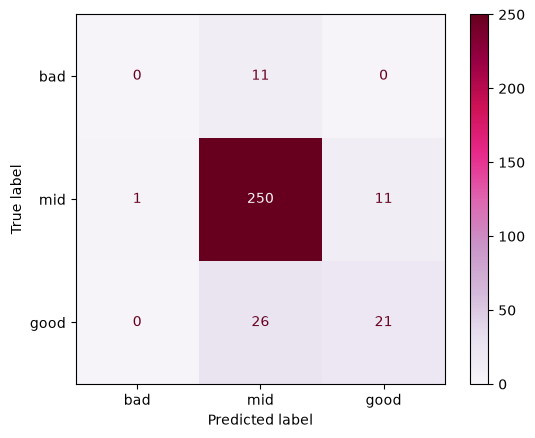

In [24]:
labels = ['bad', 'mid', 'good']

matriz_confusion = confusion_matrix(y_test, y_pred, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=matriz_confusion, display_labels=labels)

disp.plot(cmap=plt.cm.PuRd)
plt.show()


La matriz de confusión da cuenta que el dataset esta muy desbalanceado.

**classification_report**

In [25]:
report = classification_report(y_test, y_pred, target_names=labels)

print(report)

              precision    recall  f1-score   support

         bad       0.00      0.00      0.00        11
         mid       0.66      0.45      0.53        47
        good       0.87      0.95      0.91       262

    accuracy                           0.85       320
   macro avg       0.51      0.47      0.48       320
weighted avg       0.81      0.85      0.82       320



### Paso 4: Optimización de k.

**Guarda los resultados en una lista.**

In [26]:
k = []

accuracies = []

for i in range(1, 21):
    modelk = KNeighborsClassifier(n_neighbors=i)
    modelk.fit(X_train_esc, y_train)
    y_pred = modelk.predict(X_test_esc)
    accuracies.append(accuracy_score(y_test, y_pred))
    k.append(i)

**Grafica accuracy vs k para encontrar el mejor valor.**

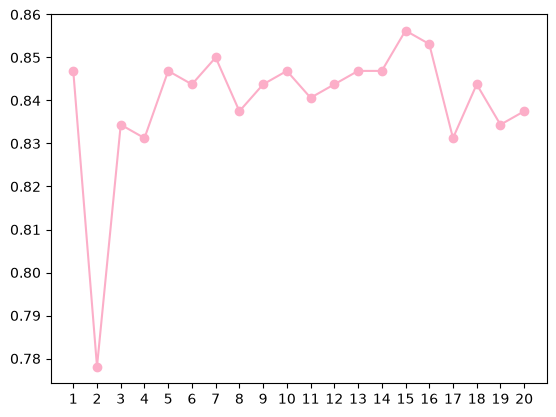

In [29]:
plt.plot(k, accuracies, marker='o', color='#fcaec8')
plt.xticks(k)
plt.show()

### ¿Te sientes confiado/a?

**Crea una función que reciba valores numéricos y prediga la calidad**

In [31]:
def predict_wine_quality(lista):
    datos = np.array(lista)
    datos= datos.reshape(1, -1)
    datos_esc = scaler.transform(datos)
    prediccion = model.predict(datos_esc)[0]
    traducciones = {
        'bad' : 'Este vino es de baja calidad',
        'mid' : 'Este vino es de calidad media',
        'good': 'Este vino es de excelente calidad'
    }

    return traducciones.get(prediccion)

In [32]:
predict_wine_quality([7.4, 0.7, 0.0, 1.9, 0.076, 11.0, 34.0, 0.9978, 3.51, 0.56, 9.4])

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


'Este vino es de calidad media'